# 22. Projeto de previsão com M4 diário: desenvolvimento, custo e retomada

**Objetivo e requisitos.** Conduzir um projeto de previsão desde a definição da amostra até a entrega dos resultados: auditar os dados, preparar a validação temporal, executar quatro procedimentos de seleção, medir cobertura e custo e retomar a execução pelo banco SQLite. Usamos dados reais do M4 diário, protocolo A (14 passos de uma vez), uma semente e orçamento `smoke`. Requer a versão da AutoHybTS que acompanha este tutorial e os extras `notebook,stats,plot`; a primeira execução baixa metadados e treino.

O projeto trabalha somente com o **treino oficial**. Um bloco final desse histórico é reservado para avaliação interna; o teste oficial não é baixado nem lido. Esta etapa dimensiona o funcionamento e o custo antes de ampliar o estudo. Os artefatos são gerados em uma pasta relativa à execução, definida abaixo.

In [1]:
import hashlib
import json
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.benchmarks import ablation_report, benchmark_cases, run_ablation
from autohybts.persistence.manifest import json_safe

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Dados e protocolo

Primeiro fixamos as decisões que precisam ser reproduzidas: quantidade de séries, semente de amostragem, sementes dos modelos, extensão máxima do histórico e orçamento. A amostra é sorteada pelo provedor com a semente declarada; os identificadores vêm dos dados, sem escolher séries manualmente. Retemos até 730 observações por série para controlar o custo desta etapa. O horizonte de 14 passos e o período de escala do MASE vêm do provedor M4 diário.

A variante A prevê o bloco inteiro a partir de uma origem. A busca considera persistência, persistência sazonal e regressão linear, com corretores lineares sobre janelas de sete resíduos fora da amostra. MASE orienta a seleção; MAE, RMSE e sMAPE também são registrados. Os limiares são fixados antes da avaliação interna: ganho mediano de 5%, taxa de vitórias de 60%, variabilidade de 5% e cobertura integral. A pequena constante `epsilon` estabiliza os cálculos da política.

A pasta de saída identifica esta execução. Ao mudar dados, código ou configuração, use outra pasta; o checkpoint verifica a compatibilidade antes de reutilizar resultados.

In [2]:
CONFIG = {
    "schema": "autohybts-ablation-config/1",
    "preset": "research",
    "dataset": "m4-daily",
    "n_series": 3,
    "sampling_seed": 0,
    "seeds": [0],
    "budget": "smoke",
    "outer_folds": 1,
    "development_only": True,
    "development_tail": 730,
    "space": {
        "variant": "A",
        "fold": "auto",
        "profile": "standard",
        "n_jobs": 1,
        "base_models": ["naive", "seasonal_naive", "linear"],
        "correctors": ["linear"],
        "residual_sources": ["historical_oof_1step"],
        "residual_windows": [7],
        "alphas": [1.0],
        "metrics": ["MASE", "MAE", "RMSE", "sMAPE"],
        "median_gain_threshold": 0.05,
        "win_rate_threshold": 0.6,
        "variability_threshold": 0.05,
        "min_coverage": 1.0,
        "epsilon": 1e-12,
    },
}

assert CONFIG["dataset"] == "m4-daily"
assert CONFIG["development_only"] is True
OUT = Path("artifacts") / "m4-development-project"
OUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT = OUT / "state.sqlite"

policy_keys = [
    "median_gain_threshold",
    "win_rate_threshold",
    "variability_threshold",
    "min_coverage",
    "epsilon",
]
display(pd.Series({key: CONFIG["space"][key] for key in policy_keys}, name="threshold"))
print("Sample size:", CONFIG["n_series"], "seeds:", CONFIG["seeds"], "budget:", CONFIG["budget"])

median_gain_threshold    5.000000e-02
win_rate_threshold       6.000000e-01
variability_threshold    5.000000e-02
min_coverage             1.000000e+00
epsilon                  1.000000e-12
Name: threshold, dtype: float64

Sample size: 3 seeds: [0] budget: smoke


## 2. Exploração causal e auditoria

Antes de buscar modelos, verificamos o histórico disponível: comprimento, valores finitos, ordenação, duplicidade e regularidade dos timestamps. `development_only=True` carrega somente o treino oficial e reserva seu bloco final para avaliação interna. O calendário é o fornecido pelo provedor; um índice regular não comprova datas originais.

Leia a tabela antes de prosseguir: `original_train_length` é o tamanho original; os demais campos descrevem o histórico retido e os problemas encontrados. Um estado bloqueado impede a execução. Avisos exigem avaliar se o histórico sustenta as origens desejadas, sem preencher ou excluir observações automaticamente. Esta auditoria não usa o teste oficial para decidir a amostra.

In [3]:
cases = list(
    benchmark_cases(
        "m4",
        "daily",
        CONFIG["n_series"],
        CONFIG["sampling_seed"],
        development_only=True,
        development_tail=CONFIG["development_tail"],
    )
)
assert all(case.source["official_test_accessed"] is False for case in cases)
audit = pd.DataFrame(
    [
        {
            "series_id": case.series_id,
            "horizon": case.horizon,
            "seasonal_period": case.seasonal_period,
            "original_train_length": case.source["original_train_length"],
            **case.source["data_audit"],
        }
        for case in cases
    ]
)
display(audit)
assert audit["status"].isin(["READY", "READY_WITH_WARNINGS"]).all()

,series_id,horizon,seasonal_period,original_train_length,status,observations,missing,nonfinite,duplicate_timestamps,chronological,regular,start,end,constant
0,D2692,14,1,4197,READY,730,0,0,0,True,True,2010-09-26 00:00:00,2012-09-24 00:00:00,False
1,D2161,14,1,172,READY,172,0,0,0,True,True,2002-12-23 00:00:00,2003-06-12 00:00:00,False
2,D3594,14,1,4197,READY,730,0,0,0,True,True,2010-09-26 00:00:00,2012-09-24 00:00:00,False


## 3. Controles e modelos propostos

A comparação muda o procedimento de seleção, mantendo dados, horizonte, métrica e orçamento comuns:

| Procedimento | Decisão |
| --- | --- |
| `lowest_error` | Escolhe o finalista com menor erro médio em `V_select`. |
| `incremental` | Aceita complexidade adicional somente quando passa na política incremental. |
| `incremental_simple` | Aplica essa política restringindo as estruturas a até dois modelos ajustados. |
| `guarded_nested` | Acrescenta uma validação aninhada; se o procedimento não superar a referência individual, conserva essa referência. |

A referência individual é o modelo isolado com menor erro em `V_select`; persistência e persistência sazonal também têm seus erros registrados. Não são quatro buscas independentes: alguns procedimentos compartilham trabalho.

Antes da execução, `fit` prepara o plano temporal, sem rodar a busca. `V_search` ajusta as candidatas e `V_select` decide entre elas; o bloco final fica fora dessas decisões. `fold="auto"` adapta o número de origens ao histórico. A primeira tabela mostra quantas origens cada série permite no plano principal e na primeira dobra interna. A segunda expõe os limites dos splits. Confira os avisos, especialmente quando o histórico reduz o número de origens.

In [4]:
plans, split_tables, preflight_messages = [], {}, []
for case in cases:
    settings = {
        **CONFIG["space"],
        "fh": case.horizon,
        "seasonal_period": case.seasonal_period,
        "budget": CONFIG["budget"],
        "session_id": CONFIG["seeds"][0],
    }
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        exp = AutoHybridExperiment(**settings, test_size=case.test_size).fit(case.values)
        inner = AutoHybridExperiment(**settings, test_size=0).fit(
            case.values.iloc[: -case.test_size - CONFIG["outer_folds"] * case.horizon]
        )
    assert exp.history_.end < case.values.index[-case.test_size]
    split_tables[case.series_id] = exp.splits
    plans.append(
        {
            "series_id": case.series_id,
            "folds_per_layer": exp.fold_,
            "earliest_inner_folds": inner.fold_,
            "horizon": case.horizon,
        }
    )
    preflight_messages.extend(str(item.message) for item in caught)
display(pd.DataFrame(plans))
display(pd.concat(split_tables, names=["series_id"]))
for message in sorted(set(preflight_messages)):
    print("WARNING:", message)

,series_id,folds_per_layer,earliest_inner_folds,horizon
0,D2692,7,7,14
1,D2161,4,4,14
2,D3594,7,7,14


layer train_start     origin first_target last_target  n_train  horizon
series_id fold_id                                                                           
D2692     search-0  search  2010-09-26 2012-02-27   2012-02-28  2012-03-12      520       14
          search-1  search  2010-09-26 2012-03-12   2012-03-13  2012-03-26      534       14
          search-2  search  2010-09-26 2012-03-26   2012-03-27  2012-04-09      548       14
          search-3  search  2010-09-26 2012-04-09   2012-04-10  2012-04-23      562       14
          search-4  search  2010-09-26 2012-04-23   2012-04-24  2012-05-07      576       14
          search-5  search  2010-09-26 2012-05-07   2012-05-08  2012-05-21      590       14
          search-6  search  2010-09-26 2012-05-21   2012-05-22  2012-06-04      604       14
          select-0  select  2010-09-26 2012-06-04   2012-06-05  2012-06-18      618       14
          select-1  select  2010-09-26 2012-06-18   2012-06-19  2012-07-02      632       14
          select-2  select  2010-09-26 2012-07-02   2012-07-03  2012-07-16      646       14
          select-3  select  2010-09-26 2012-07-16   2012-07-17  2012-07-30      660       14
          select-4  select  2010-09-26 2012-07-30   2012-07-31  2012-08-13      674       14
          select-5  select  2010-09-26 2012-08-13   2012-08-14  2012-08-27      688       14
          select-6  select  2010-09-26 2012-08-27   2012-08-28  2012-09-10      702       14
D2161     search-0  search  2002-12-23 2003-02-06   2003-02-07  2003-02-20       46       14
          search-1  search  2002-12-23 2003-02-20   2003-02-21  2003-03-06       60       14
          search-2  search  2002-12-23 2003-03-06   2003-03-07  2003-03-20       74       14
          search-3  search  2002-12-23 2003-03-20   2003-03-21  2003-04-03       88       14
          select-0  select  2002-12-23 2003-04-03   2003-04-04  2003-04-17      102       14
          select-1  select  2002-12-23 2003-04-17   2003-04-18  2003-05-01      116       14
          select-2  select  2002-12-23 2003-05-01   2003-05-02  2003-05-15      130       14
          select-3  select  2002-12-23 2003-05-15   2003-05-16  2003-05-29      144       14
D3594     search-0  search  2010-09-26 2012-02-27   2012-02-28  2012-03-12      520       14
          search-1  search  2010-09-26 2012-03-12   2012-03-13  2012-03-26      534       14
          search-2  search  2010-09-26 2012-03-26   2012-03-27  2012-04-09      548       14
          search-3  search  2010-09-26 2012-04-09   2012-04-10  2012-04-23      562       14
          search-4  search  2010-09-26 2012-04-23   2012-04-24  2012-05-07      576       14
          search-5  search  2010-09-26 2012-05-07   2012-05-08  2012-05-21      590       14
          search-6  search  2010-09-26 2012-05-21   2012-05-22  2012-06-04      604       14
          select-0  select  2010-09-26 2012-06-04   2012-06-05  2012-06-18      618       14
          select-1  select  2010-09-26 2012-06-18   2012-06-19  2012-07-02      632       14
          select-2  select  2010-09-26 2012-07-02   2012-07-03  2012-07-16      646       14
          select-3  select  2010-09-26 2012-07-16   2012-07-17  2012-07-30      660       14
          select-4  select  2010-09-26 2012-07-30   2012-07-31  2012-08-13      674       14
          select-5  select  2010-09-26 2012-08-13   2012-08-14  2012-08-27      688       14
          select-6  select  2010-09-26 2012-08-27   2012-08-28  2012-09-10      702       14

## 4. Busca e seleção

`run_ablation` executa os procedimentos nas mesmas unidades série × semente. O bloco final do desenvolvimento serve apenas para avaliar a escolha feita antes dele. A guarda aninhada decide usando dobras anteriores a esse bloco. O orçamento `smoke` é uma execução pequena do fluxo real; sua precisão não representa uma busca ampla.

O banco registra cada caso completo. Se já existir um checkpoint compatível, `resume=True` reutiliza os casos concluídos. Falhas ficam registradas por `on_error="record"`; a cobertura permite distinguir ausência de resultado de desempenho ruim. `n_jobs=1` e o limite de uma thread BLAS reduzem a concorrência para tornar o custo mais fácil de interpretar.

Ao terminar, esperamos um caso concluído por série × semente e quatro linhas por caso. Os avisos são exibidos, e as verificações abaixo interrompem o fluxo se faltar um resultado previsto.

In [5]:
arguments = dict(
    seeds=CONFIG["seeds"],
    budget=CONFIG["budget"],
    space=CONFIG["space"],
    outer_folds=CONFIG["outer_folds"],
    checkpoint=CHECKPOINT,
    configuration=CONFIG,
    on_error="record",
)
started = time.perf_counter()
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
    warnings.simplefilter("always")
    table = run_ablation(cases, **arguments, resume=CHECKPOINT.exists(), progress=print)
warning_counts = Counter(str(item.message) for item in caught)
coverage = table.attrs["coverage"]
print("Invocation seconds:", round(time.perf_counter() - started, 2))
print(
    {
        key: coverage[key]
        for key in (
            "n_planned_cases",
            "n_succeeded_cases",
            "n_failed_cases",
            "n_skipped_cases",
            "n_result_rows",
        )
    }
)
display(pd.DataFrame(coverage["procedures"]).T)
for message, count in warning_counts.items():
    print(f"WARNING ({count}): {message}")
assert coverage["n_succeeded_cases"] == len(cases) * len(CONFIG["seeds"])
assert coverage["n_result_rows"] == 4 * len(cases) * len(CONFIG["seeds"])

Invocation seconds:

 0.18
{'n_planned_cases': 3, 'n_succeeded_cases': 3, 'n_failed_cases': 0, 'n_skipped_cases': 0, 'n_result_rows': 12}


,n_planned,n_succeeded,n_metric_valid,n_paired,metric_coverage,paired_coverage
lowest_error,3.0,3.0,3.0,3.0,1.0,1.0
incremental,3.0,3.0,3.0,3.0,1.0,1.0
incremental_simple,3.0,3.0,3.0,3.0,1.0,1.0
guarded_nested,3.0,3.0,3.0,3.0,1.0,1.0


## 5. Resultados e gráficos

A primeira tabela mostra o campeão de cada procedimento e seus erros: `validation_score` em `V_select`, `internal_MASE` no bloco reservado e `reference_internal_MASE` para a referência individual no mesmo bloco. Menor MASE é melhor; `gain_vs_base` positivo indica redução do erro em relação à referência. A cobertura informa a disponibilidade das unidades de validação. O nome `test_score` no CSV é o campo genérico da API; nesta configuração, ele se refere exclusivamente ao bloco interno do treino oficial.

A tabela seguinte informa estado, número de tentativas e tempo por caso. O resumo por procedimento apresenta cobertura pareada e esforço por procedimento: `candidates` conta candidatas, `units` conta unidades de avaliação e `mean_seconds` resume seu custo de busca. Cobertura pareada de 1 indica que todas as linhas têm a referência necessária à comparação.

Os gráficos relacionam tamanho do histórico e custo observado. Não some o custo dos quatro procedimentos: uma parte das buscas é compartilhada. O total por caso contabiliza o trabalho executado uma vez, incluindo etapas adicionais. O tempo da invocação atual pode ser pequeno quando o banco fornece resultados anteriores, enquanto o custo histórico continua registrado.

As métricas de previsão estão em `table` e no CSV exportado. Aqui a leitura se concentra no dimensionamento do projeto; uma amostra pequena e uma única semente não permitem concluir superioridade de um procedimento.

,series_id,procedure,champion,validation_score,internal_MASE,reference_internal_MASE,gain_vs_base,coverage
0,D2692,lowest_error,linear,2.8027,2.7242,2.7242,0.0000,1.0
1,D2692,incremental,naive,2.8875,3.0579,2.7242,-0.1225,1.0
2,D2692,incremental_simple,naive,2.8875,3.0579,2.7242,-0.1225,1.0
3,D2692,guarded_nested,linear,2.8027,2.7242,2.7242,0.0000,1.0
4,D2161,lowest_error,naive-linear,2.0855,2.4264,2.5909,0.0635,1.0
5,D2161,incremental,naive-linear,2.0855,2.4264,2.5909,0.0635,1.0
6,D2161,incremental_simple,naive-linear,2.0855,2.4264,2.5909,0.0635,1.0
7,D2161,guarded_nested,naive,2.2141,2.5909,2.5909,0.0000,1.0
8,D3594,lowest_error,naive,2.2427,0.7914,0.7914,0.0000,1.0
9,D3594,incremental,naive,2.2427,0.7914,0.7914,0.0000,1.0


,series_id,seed,status,attempts,seconds
0,D2692,0,SUCCEEDED,1,74.834
1,D2161,0,SUCCEEDED,1,2.570
2,D3594,0,SUCCEEDED,1,110.043


Unique case seconds: 187.45


,n_rows,n_paired,paired_coverage,mean_seconds,candidates,units
procedure,,,,,,
lowest_error,3,3,1.0,32.103,10.000,90.0
incremental,3,3,1.0,32.103,10.000,90.0
incremental_simple,3,3,1.0,2.903,6.000,54.0
guarded_nested,3,3,1.0,59.458,19.333,176.0


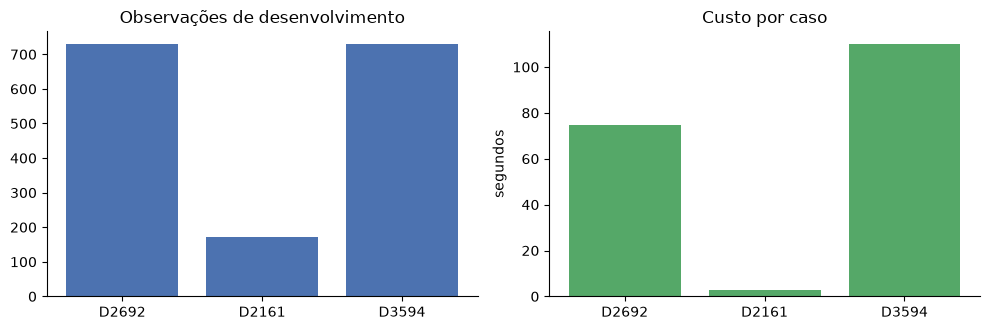

In [6]:
scores = table[
    [
        "series_id",
        "procedure",
        "champion",
        "validation_score",
        "test_score",
        "best_base_test",
        "gain_vs_base",
        "coverage",
    ]
].rename(columns={"test_score": "internal_MASE", "best_base_test": "reference_internal_MASE"})
display(scores.round(4))

case_cost = pd.DataFrame(
    [
        {
            "series_id": state["series_id"],
            "seed": state["seed"],
            "status": state["status"],
            "attempts": len(state["history"]),
            "seconds": sum(attempt.get("seconds") or 0 for attempt in state["history"]),
        }
        for state in table.attrs["cases"]
    ]
)
assert abs(case_cost["seconds"].sum() - coverage["known_seconds_total"]) < 1e-6
display(case_cost.round(3))
print("Unique case seconds:", round(coverage["known_seconds_total"], 2))
columns = ["n_rows", "n_paired", "paired_coverage", "mean_seconds", "candidates", "units"]
display(ablation_report(table)[columns].round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(audit["series_id"], audit["observations"], color="#4C72B0")
axes[0].set_title("Observações de desenvolvimento")
axes[1].bar(case_cost["series_id"], case_cost["seconds"], color="#55A868")
axes[1].set_title("Custo por caso")
axes[1].set_ylabel("segundos")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "pilot_cost.png", dpi=120, bbox_inches="tight")
fig.savefig(OUT / "pilot_cost.svg", bbox_inches="tight")
plt.show()

## 6. Diagnóstico e limites

A retomada faz parte do fluxo do projeto: uma interrupção não deve exigir repetir casos concluídos. Chamamos a mesma execução novamente e verificamos duas propriedades: o CSV permanece idêntico e o número de tentativas não cresce. Essa verificação mede reutilização do checkpoint; ela não é uma segunda medição do custo de treinamento.

Históricos truncados, poucas séries, uma semente e um orçamento reduzido limitam a generalização. A quantidade de origens pode variar entre séries. Tempos dependem da máquina, da inicialização e dos caches. Antes de ampliar o projeto, fixe regras para históricos curtos e aumente a amostra e o orçamento dentro dos recursos disponíveis.

In [7]:
before_csv = table.to_csv(index=False).encode("utf-8")
before_attempts = coverage["n_attempts"]
with threadpool_limits(limits=1):
    reused = run_ablation(cases, **arguments, resume=True)
assert reused.to_csv(index=False).encode("utf-8") == before_csv
assert reused.attrs["coverage"]["n_attempts"] == before_attempts
print(
    {
        "csv_identical": True,
        "new_attempts": 0,
        "reused_cases": reused.attrs["coverage"]["n_succeeded_cases"],
    }
)

{'csv_identical': True, 'new_attempts': 0, 'reused_cases': 3}


## 7. Avaliação interna e entrega

A avaliação do bloco reservado já ocorreu em `run_ablation`, depois da seleção. Não há nova leitura desse bloco nesta etapa: exportamos os resultados existentes. O teste oficial continua fora do projeto; sua avaliação deve ocorrer somente após congelar o desenho do estudo ampliado.

O CSV contém as métricas por série, semente e procedimento. O protocolo resolvido guarda configuração, cobertura, planos temporais e avisos. O manifesto identifica ambiente e fontes e registra hashes dos arquivos. O SQLite permite retomar os casos. As figuras e os splits acompanham a entrega, permitindo revisar tanto os resultados quanto o caminho usado para obtê-los.

In [8]:
table.to_csv(OUT / "results.csv", index=False)
audit.to_csv(OUT / "data_audit.csv", index=False)
for series_id, splits in split_tables.items():
    splits.reset_index().to_csv(OUT / f"{series_id}-splits.csv", index=False)
protocol = {
    **table.attrs["protocol"],
    "resolved_cases": table.attrs["cases"],
    "coverage": coverage,
    "temporal_preflight": plans,
    "preflight_warnings": sorted(set(preflight_messages)),
    "execution_warnings": dict(warning_counts),
    "threadpool_limit": 1,
    "official_test_accessed": False,
}
(OUT / "resolved_protocol.json").write_text(
    json.dumps(json_safe(protocol), indent=2, ensure_ascii=False, allow_nan=False),
    encoding="utf-8",
)
files = [
    "results.csv",
    "data_audit.csv",
    "resolved_protocol.json",
    "state.sqlite",
    "pilot_cost.png",
    "pilot_cost.svg",
    *[f"{case.series_id}-splits.csv" for case in cases],
]
manifest = {
    "study_id": protocol["study_id"],
    "source_fingerprint": protocol["source_fingerprint"],
    "environment": protocol["environment"],
    "resume_csv_identical": True,
    "sha256": {name: hashlib.sha256((OUT / name).read_bytes()).hexdigest() for name in files},
}
(OUT / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Output:", OUT.as_posix())
print(sorted([*files, "manifest.json"]))

Output: artifacts/m4-development-project
['D2161-splits.csv', 'D2692-splits.csv', 'D3594-splits.csv', 'data_audit.csv', 'manifest.json', 'pilot_cost.png', 'pilot_cost.svg', 'resolved_protocol.json', 'results.csv', 'state.sqlite']


## 8. Leitura

**Execução registrada.** 3 casos concluídos, 12 linhas e 0 falhas. O trabalho executado somou 187.4 segundos. Os planos principais comportaram 4, 7 origens por camada, conforme o histórico disponível; a redução de origens permanece sinalizada. A retomada preservou o CSV e não criou tentativas novas. Esses tempos descrevem esta execução.

- **Funcionamento.** Confira os casos planejados e concluídos e as quatro linhas por caso. Falhas ou cobertura incompleta precisam ser resolvidas antes de ampliar a execução.
- **Dados e validação.** A auditoria e os planos mostram quanto histórico entrou e quantas origens foram possíveis. Avisos sobre séries curtas devem orientar uma regra explícita para a próxima etapa.
- **Custo.** Use o total por caso para dimensionar recursos. Os valores por procedimento incluem trabalho compartilhado e não devem ser somados como execuções independentes.
- **Continuidade.** A segunda chamada deve mostrar reutilização dos casos, nenhuma tentativa nova e CSV idêntico.
- **Próxima decisão.** Fixe tamanho da amostra, orçamento, tratamento de séries curtas e comparadores antes do estudo ampliado. Os resultados desta etapa não sustentam uma classificação de precisão generalizável.